# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
%pip install nltk

  Using cached nltk-3.10.3-py3-none-any.whl.metadata (3.2 kB)
Using cached nltk-3.10.3-py3-none-any.whl (1.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [nltk]━━━━━━ 1/2 [nltk]
Note: you may need to restart the kernel to use updated packages.


In [2]:
ROLL_NO = 1024170265          # <-- your full roll number
NAME = "Harshit Goyal"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170265   Name: Harshit Goyal   Fingerprint: FCF1A91A   Tickets: 12

Ticket_ID                                                                Ticket_Text
      T01                The projector failed to open. It works on another computer.
      T02                                    The LMS failed to open. This is urgent.
      T03                                      It's not the laptop; it's the server.
      T04 Python failed to open while uploading the file. Is there another solution?
      T05                       The MATLAB has stopped syncing. It worked yesterday.
      T06                                              The LMS says 'Not Submitted'.
      T07                             The printer is not working. Please resolve it.
      T08                                       Python 3.12 was installed yesterday.
      T09                        VPN failed to open on my laptop. Please resolve it.
      T10    Laptop stopped responding after the latest update. I

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
import pandas as pd

rows = []
processed = []

for _, row in df.iterrows():
  res = process_ticket(row['Ticket_Text'])
  processed.append(res)
  rows.append({
      'Ticket_ID': row['Ticket_ID'],
      'Sentences': len(res['sentences']),
      'Tokens': len(res['tokens']),
      'Punctuation': len(res['punct']),
      'Stopwords': len(res['stops']),
      'Unique_Tokens': len(set(res['tokens'])),
      'Final_Tokens': len(res['final']),
  })

table_df = pd.DataFrame(rows)

# Add TOTAL row
total_row = {
    'Ticket_ID': 'TOTAL',
    'Sentences': table_df['Sentences'].sum(),
    'Tokens': table_df['Tokens'].sum(),
    'Punctuation': table_df['Punctuation'].sum(),
    'Stopwords': table_df['Stopwords'].sum(),
    'Unique_Tokens': '-',
    'Final_Tokens': table_df['Final_Tokens'].sum(),
}
summary_table = pd.concat(
    [table_df, pd.DataFrame([total_row])], ignore_index=True
)
print(summary_table.to_string(index=False))

# Breakdown for ticket T03
t03_res = processed[2]  # index 2 corresponds to T03
print("\n--- Detailed Breakdown for Ticket T03 ---")
print("Ticket Text: ", df.loc[2, "Ticket_Text"])
print("Tokens:      ", t03_res["tokens"])
print("Punctuation: ", t03_res["punct"])
print("Stopwords:   ", t03_res["stops"])
print("Final Tokens:", t03_res["final"])

Ticket_ID  Sentences  Tokens  Punctuation  Stopwords Unique_Tokens  Final_Tokens
      T01          2      12            2          4            11             6
      T02          2      10            2          4             9             4
      T03          1      11            2          5             8             4
      T04          2      14            2          5            14             7
      T05          2      10            2          3             9             5
      T06          1       8            3          2             7             3
      T07          2      10            2          4             9             4
      T08          1       6            1          1             6             4
      T09          2      12            2          4            11             6
      T10          2      12            2          3            11             7
      T11          2      11            2          3            11             6
      T12          1       9

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* In ticket T03 (It's not the laptop; it's the server.), the token "'s" appears twice in the final tokens.   
This happens because word_tokenize() splits the contraction "It's" into "It" and "'s" according to standard Penn Treebank conventions. While "it" is recognized as a stopword and removed, "'s" contains alphanumeric characters, so is_punct() returns False. Because "'s" is also not included in the standard NLTK English stopword list, it passes through to the final token list.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code

all_texts = list(df["Ticket_Text"]) + TEST_LINES
corpus_text = " ".join(all_texts)

# 1. Extraction regex patterns
pattern_longer_5 = r"\b[A-Za-z]{6,}\b"
pattern_numbers = r"\b\d+(?:\.\d+)+(?:%|\b)|\b\d+(?:,\d{3})*(?:%|\b)"
pattern_capitalized = r"\b[A-Z][a-zA-Z]*\b"
pattern_vowel_start = r"\b[aeiouAEIOU][a-zA-Z]*\b"

print(
    "Words longer than 5 letters:",
    sorted(list(set(re.findall(pattern_longer_5, corpus_text)))),
)
print(
    "Numbers (including decimals/versions):",
    list(set(re.findall(pattern_numbers, corpus_text))),
)
print(
    "Capitalized words:",
    sorted(list(set(re.findall(pattern_capitalized, corpus_text)))),
)
print(
    "Words starting with a vowel:",
    sorted(list(set(re.findall(pattern_vowel_start, corpus_text)))),
)

# 2. Replacement regex patterns
email_regex = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_regex = r"(?:https?://[^\s,;]+|www\.[^\s,;]+)"
phone_regex = (
    r"(?:\+?\d{1,3}[-.\s]?)?\(?\d{2,5}\)?[-.\s]?\d{3,5}[-.\s]?\d{4}"
)

print("\n--- Replacements on TEST_LINES ---")
for line in TEST_LINES:
  res = re.sub(email_regex, "<EMAIL>", line)
  res = re.sub(url_regex, "<URL>", res)
  res = re.sub(phone_regex, "<PHONE>", res)
  print(res)

print("\n--- Replacement on Ticket T12 ---")
t12_text = df.loc[df["Ticket_ID"] == "T12", "Ticket_Text"].iloc[0]
res_t12 = re.sub(email_regex, "<EMAIL>", t12_text)
res_t12 = re.sub(url_regex, "<URL>", res_t12)
print("Original:", t12_text)
print("Masked:  ", res_t12)

Words longer than 5 letters: ['Laptop', 'MATLAB', 'Matlab', 'Please', 'Python', 'Submitted', 'Version', 'another', 'computer', 'failed', 'helpdesk', 'installed', 'laptop', 'latest', 'printer', 'projector', 'resolve', 'responding', 'server', 'several', 'solution', 'stopped', 'syncing', 'thapar', 'update', 'uploading', 'urgent', 'worked', 'working', 'yesterday']
Numbers (including decimals/versions): ['3.12', '43210', '1,250', '91', '239', '2.0.1', '5.30', '3201', '0175', '98765', '95.5%']
Capitalized words: ['Call', 'I', 'Is', 'It', 'LMS', 'Laptop', 'MATLAB', 'Mail', 'Matlab', 'Not', 'Please', 'Python', 'Rs', 'Submitted', 'The', 'This', 'VPN', 'Version', 'Write']
Words starting with a vowel: ['I', 'Is', 'It', 'a', 'ac', 'after', 'another', 'art', 'at', 'edu', 'in', 'installed', 'is', 'isn', 'it', 'of', 'on', 'open', 'or', 'univ', 'update', 'uploading', 'urgent']

--- Replacements on TEST_LINES ---
Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>
Call <PHONE>0, <PHONE>0 or <PHONE>. Version 

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* In this dataset, there are 8 distinct words capitalized strictly due to sentence-initial position: "The", "It", "Is", "Write", "Please", "Laptop", "This", and "Python" (in T04). True proper nouns and domain identifiers that remain capitalized in any position are "LMS", "MATLAB", "Matlab", "VPN", and "Python" (in T08). Therefore, approximately 61.5% of all capitalized word types in the dataset are capitalized only because they appear at the start of a sentence.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [8]:
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

# Preserves URLs, emails, phone numbers, version/decimals, hyphenated words, contractions, and words
pattern = r"""(?x)
    (?:https?://|www\.)[^\s,;()]+
    |[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+
    |\+?\d{1,3}[-.\s]\d{5}[-.\s]\d{5}|\d{4}-\d{3}-\d{4}
    |\d+(?:\.\d+)+%?
    |[a-zA-Z]+(?:-[a-zA-Z]+)+
    |[a-zA-Z]+(?:'[a-zA-Z]+)?
    |\d+
    |[^\w\s]
"""

tokenizer = RegexpTokenizer(pattern)


def my_tokenize(text):
  return tokenizer.tokenize(text)


print("--- Comparing on TEST_LINES ---")
for idx, line in enumerate(TEST_LINES):
  print(f"\nLine {idx+1}:")
  print("my_tokenize:   ", my_tokenize(line))
  print("word_tokenize: ", word_tokenize(line))

# Comparison across your 12 tickets
diff_tickets = []
for _, row in df.iterrows():
  t_my = my_tokenize(row["Ticket_Text"])
  t_nltk = word_tokenize(row["Ticket_Text"])
  if t_my != t_nltk:
    diff_tickets.append(row["Ticket_ID"])

print(
    f"\nNumber of tickets tokenized differently: {len(diff_tickets)} /"
    f" {len(df)}"
)
print("Different ticket IDs:", diff_tickets)

--- Comparing on TEST_LINES ---

Line 1:
my_tokenize:    ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize:  ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Line 2:
my_tokenize:    ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize:  ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Line 3:
my_tokenize:    ['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
word_tokenize:  ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 3 tickets (T03, T08, and T12) are tokenized differently:   
Contractions (Ticket T03): word_tokenize("It's") produces ['It', "'s"]. my_tokenize keeps "It's" intact as a single token.   

Decimals and Versions (Ticket T08): word_tokenize("3.12") splits the number into three tokens ['3', '.', '12']. my_tokenize retains "3.12" as a single numeric token.   
          
URLs and Emails (Ticket T12): word_tokenize splits "it.helpdesk@thapar.edu" and "www.thapar.edu/it" at every dot and slash symbol (['it.helpdesk', '@', 'thapar.edu'], ['www.thapar.edu', '/', 'it']). my_tokenize preserves both entities as single atomic tokens.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
# Your code

import nltk
from nltk.corpus import wordnet
from nltk.stem import LancasterStemmer, PorterStemmer, RegexpStemmer, WordNetLemmatizer
import pandas as pd


def get_wordnet_pos(treebank_tag):
  if treebank_tag.startswith("J"):
    return wordnet.ADJ
  elif treebank_tag.startswith("V"):
    return wordnet.VERB
  elif treebank_tag.startswith("N"):
    return wordnet.NOUN
  elif treebank_tag.startswith("R"):
    return wordnet.ADV
  else:
    return wordnet.NOUN


# 1. Collect unique final tokens
unique_final = sorted(
    list(
        set(
            token
            for text in df["Ticket_Text"]
            for token in process_ticket(text)["final"]
        )
    )
)

porter = PorterStemmer()
lancaster = LancasterStemmer()
# Rule selected: strip '(ing|ed)$' based on 'syncing'/'working' and 'installed'/'submitted'
regexp_stemmer = RegexpStemmer(r"(ing|ed)$", min=4)
lemmatizer = WordNetLemmatizer()

pos_dict = dict(nltk.pos_tag(unique_final))

# 2. Build comparison table
diff_rows = []
for word in unique_final:
  wn_tag = get_wordnet_pos(pos_dict[word])
  p = porter.stem(word)
  l = lancaster.stem(word)
  r = regexp_stemmer.stem(word)
  w = lemmatizer.lemmatize(word, pos=wn_tag)

  if len({p, l, r, w}) > 1:
    diff_rows.append({
        "Word": word,
        "POS": pos_dict[word],
        "Porter": p,
        "Lancaster": l,
        "Regexp": r,
        "WordNet_POS": w,
    })

comparison_df = pd.DataFrame(diff_rows)
print(f"Total words with differing outputs: {len(comparison_df)}")
print(comparison_df.to_string(index=False))

Total words with differing outputs: 25
     Word POS    Porter Lancaster    Regexp WordNet_POS
  another  DT     anoth     anoth   another     another
 computer  NN    comput    comput  computer    computer
     file  NN      file       fil      file        file
installed VBN    instal    instal   install      instal
   latest JJS    latest    latest    latest        late
      lms  NN        lm       lms       lms          lm
     open  JJ      open        op      open        open
   please  NN     pleas     pleas    please      please
  printer  NN   printer     print   printer     printer
projector  NN projector   project projector   projector
  resolve VBP    resolv    resolv   resolve     resolve
     says VBZ       say       say      says         say
   server  RB    server      serv    server      server
  several  JJ     sever       sev   several     several
 solution  NN     solut      solv  solution    solution
  stopped VBD      stop      stop     stopp        stop
submitted

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* Regexp Stemmer Justification: Suffix pattern r'(ing|ed)$' with min=4 is chosen based on verbs in this dataset: "working", "syncing", "uploading" and "installed", "submitted".   
Over-stemming Example:
For the word yesterday, Lancaster aggressive reduction produces yester, cutting letters beyond the root morphological morpheme.

Under-stemming Example:
For the word server, the Porter Stemmer leaves it as server, and RegexpStemmer leaves it as server, whereas Lancaster over-stems it to serv. Another example is stopped, where Porter produces stop and Lancaster produces stop, but RegexpStemmer strips only "ed" leaving the double-consonant non-root stopp

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

=== Corpus Statistics ===
       Corpus  Total Tokens  Unique Tokens    TTR
     S1 (All)           125             62 0.4960
S2 (No Punct)           101             56 0.5545
   S3 (Final)            61             40 0.6557
  S4 (Porter)            61             38 0.6230

--- Top 10 Words in S1 ---
.: 18
the: 10
it: 7
to: 5
failed: 4
open: 4
is: 3
not: 3
laptop: 3
stopped: 3

--- Top 10 Words in S3 ---
failed: 4
open: 4
laptop: 3
stopped: 3
yesterday: 3
another: 2
lms: 2
's: 2
python: 2
matlab: 2

--- Top 5 Bigrams in S1 ---
('failed', 'to'): 4
('to', 'open'): 4
('.', 'it'): 4
('.', 'the'): 4
('yesterday', '.'): 3

--- Top 5 Bigrams in S3 ---
('failed', 'open'): 4
('matlab', 'stopped'): 2
('worked', 'yesterday'): 2
('please', 'resolve'): 2
('stopped', 'responding'): 2


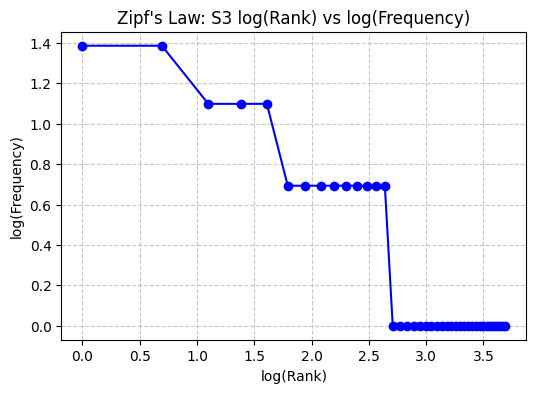

In [10]:
# Your code
from collections import Counter
import matplotlib.pyplot as plt
from nltk import bigrams
from nltk.stem import PorterStemmer
import numpy as np
import pandas as pd

# S1: all tokens
s1 = [t for text in df['Ticket_Text'] for t in process_ticket(text)['tokens']]

# S2: tokens without punctuation
s2 = [
    t
    for text in df['Ticket_Text']
    for t in process_ticket(text)['tokens']
    if not is_punct(t)
]

# S3: final tokens
s3 = [t for text in df['Ticket_Text'] for t in process_ticket(text)['final']]

# S4: S3 after Porter stemming
ps = PorterStemmer()
s4 = [ps.stem(t) for t in s3]

corpora = {'S1 (All)': s1, 'S2 (No Punct)': s2, 'S3 (Final)': s3, 'S4 (Porter)': s4}

stats = []
for name, tokens in corpora.items():
  tot = len(tokens)
  uniq = len(set(tokens))
  ttr = uniq / tot if tot > 0 else 0
  stats.append({
      'Corpus': name,
      'Total Tokens': tot,
      'Unique Tokens': uniq,
      'TTR': round(ttr, 4),
  })

stats_df = pd.DataFrame(stats)
print("=== Corpus Statistics ===")
print(stats_df.to_string(index=False))

print("\n--- Top 10 Words in S1 ---")
for word, count in Counter(s1).most_common(10):
  print(f"{word}: {count}")

print("\n--- Top 10 Words in S3 ---")
for word, count in Counter(s3).most_common(10):
  print(f"{word}: {count}")

print("\n--- Top 5 Bigrams in S1 ---")
for bg, count in Counter(list(bigrams(s1))).most_common(5):
  print(f"{bg}: {count}")

print("\n--- Top 5 Bigrams in S3 ---")
for bg, count in Counter(list(bigrams(s3))).most_common(5):
  print(f"{bg}: {count}")

# Plot log(rank) vs log(frequency) for S3
counts = [count for _, count in Counter(s3).most_common()]
ranks = list(range(1, len(counts) + 1))

plt.figure(figsize=(6, 4))
plt.plot(np.log(ranks), np.log(counts), marker='o', color='b')
plt.title("Zipf's Law: S3 log(Rank) vs log(Frequency)")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.grid(True, linestyle="--", alpha=0.7)
plt.show()

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* S1 → S2 (Increases): High-frequency punctuation tokens (., ;, ') are removed. Removing these recurring non-word tokens decreases total token count significantly without reducing word variety, increasing the Type-Token Ratio (TTR).   


S2 → S3 (Increases substantially): Closed-class stopwords (the, to, is, it, on) make up a large portion of repeated tokens. Removing them reduces the total count (denominator) far more than the unique count (numerator), yielding the highest TTR.   


S3 → S4 (Decreases): The Porter Stemmer maps morphological variants to identical root stems (e.g., "worked", "working" → "work"; "open", "opening" → "open"). This reduces the unique token count (numerator) while the total token count remains unchanged, decreasing the TTR.   
